## Pegasus Evaluation: SLO-based Composition Planning

Section C.2. Each application (vision, audio, lidar) has five compositions, V1 to V5, A1 to A5 and L1 to L5: the chains `b1u-<application>-<i>` of the second campaign. A client states SLOs on three dimensions, and a grid search over the compositions and their configurations picks the best one that meets them. C.2a to C.2c infer the configurations from the models of B.1; C.2d compares the plans that were deployed on the testbed with the latencies of their requests. Implementation: `slo_planning.py`.

**Configuration** of a composition with $K$ services:
- $q$, the data quality of every service (knob `data_quality`): image width in pixels (vision), clip length in seconds (audio), point cloud radius in meters (lidar);
- $w_k \in \{1, \dots, 4\}$, the workers of service $k$ (knob `parallelism`); deployed with $w_k + 0.5$ cores;
- $m_k \in \{1, 2\}$, the model size of each vision detector (knob `model_size`).

**SLO dimensions:**
- *cost*: the total workers $\sum_k w_k$;
- *latency*: the Pegasus bound on the p95 of the end-to-end latency at the scenario's arrival rate $\lambda$ (items/s, Poisson), from the load-aware models of B.1. Each service gets the violation probability $\varepsilon = \alpha / K$ with $\alpha = 0.05$, and the end-to-end bound is the sum of the $K$ node bounds; a configuration with an overloaded service has no finite bound and is infeasible;
- *quality*: $q$ (and, for vision, a smallest model size).

A **scenario** has its own $\lambda$, constrains one or two dimensions, optimizes the free ones with a weight each, and requires one or two capabilities (only compositions that contain them are candidates). The models are trained on the benchmark runs with one to four workers only, without any run of a chain.

In [1]:
import pandas as pd
from IPython.display import Markdown, display

import slo_planning as sp
from slo_planning import Scenario

WORKER_BUDGET = 8                  # workers; the budget of a trade-off panel in C.2c for a scenario without a worker limit
# False: do not write the figures c2_slo_plans_<application>. They show the plans of the earlier deployment (see
# statics/slo_planning/README.md), which the current models do not reproduce.
WRITE_DEPLOYED_FILES = False

### C.2a. Scenarios

Five scenarios per application (S-V-1 to S-L-5), each with an arrival rate (items/s), constraints, a weight for every free dimension and the capabilities it requires. The table below lists them with their candidate compositions (those that contain every required capability), the number of grid configurations (`configurations`, summed over the candidates) that the grid search of C.2b evaluates, and the *typical value* of each dimension: its median over all grid configurations of the candidates that meet the constraints (`sp.typical_scales`).

The objective divides every dimension by its typical value, so a weight prices a *relative* change. Example: with typical values of 500 px and 500 ms and weights 1 (quality) and 0.5 (latency), 50 px more (10 %) are worth 100 ms more latency (20 %, times 0.5).

In [2]:
# Scenario(name, arrival rate in items/s, weights of the free dimensions, constraints, requires=capabilities, note=client)
SCENARIOS = {
    "vision": [
        Scenario("S-V-1 edge box", 15.0, dict(latency=0.5, quality=1.0), max_workers=6, requires=("object detection",),
                 note="a 15 fps camera with an edge box that has 6 cores for the pipeline; detects objects"),
        Scenario("S-V-2 interactive AR", 30.0, dict(cost=1.0, quality=0.5), max_latency=0.100, requires=("face detection",),
                 note="an augmented-reality face filter at 30 fps that must follow the scene within three frames"),
        Scenario("S-V-3 forensic detail", 12.0, dict(cost=1.0, latency=0.1), min_quality=512, min_model=2, requires=("object detection",),
                 note="incident review of a 12 fps camera: objects at 512 px or more with the larger model; latency matters little"),
        Scenario("S-V-4 retail analytics", 15.0, dict(cost=1.0, quality=0.5), max_latency=0.250, requires=("QR codes",),
                 note="a store camera at 15 fps that reads product codes within 250 ms"),
        Scenario("S-V-5 traffic monitoring", 25.0, dict(latency=1.0, quality=1.0), max_workers=10, requires=("motion detection",),
                 note="a roadside unit with 10 cores that detects moving vehicles in a 25 fps stream"),
    ],
    "audio": [
        Scenario("S-A-1 shared gateway", 6.0, dict(latency=0.5, quality=1.0), max_workers=4, requires=("noise suppression",),
                 note="noise suppression of 6 clips per second on a gateway that grants the pipeline 4 cores"),
        Scenario("S-A-2 voice assistant", 6.0, dict(cost=1.0, quality=0.2), max_latency=0.050, requires=("voice activity",),
                 note="a voice assistant that detects speech in 6 clips per second and must respond without a noticeable pause"),
        Scenario("S-A-3 music archive", 3.0, dict(cost=1.0, latency=0.1), min_quality=10, requires=("audio encoding",),
                 note="recordings encoded for an archive in clips of 10 s or more; latency matters little"),
        Scenario("S-A-4 call analytics", 6.0, dict(latency=1.0), max_workers=6, min_quality=6, requires=("voice activity",),
                 note="speech detection in recorded calls, 6 clips per second in clips of 6 s or more, on 6 cores; results as fast as possible"),
        Scenario("S-A-5 conferencing", 6.0, dict(cost=1.0, quality=0.5), max_latency=0.150, requires=("noise suppression",),
                 note="a conference call with noise suppression within the 150 ms mouth-to-ear budget of ITU-T G.114"),
    ],
    "lidar": [
        Scenario("S-L-1 delivery robot", 12.0, dict(latency=1.0, quality=1.0), max_workers=6, requires=("clustering",),
                 note="obstacle clusters from a 12 Hz lidar on the embedded computer of a delivery robot with 6 cores"),
        Scenario("S-L-2 collision avoidance", 12.0, dict(cost=1.0, quality=1.0), max_latency=0.080, requires=("ground removal",),
                 note="obstacles above the ground must be known before the next scan of a 12 Hz lidar (80 ms)"),
        Scenario("S-L-3 HD mapping", 12.0, dict(cost=1.0, latency=0.1), min_quality=30, requires=("registration",),
                 note="offline map building from registered scans with a radius of 30 m or more; latency matters little"),
        Scenario("S-L-4 fleet perception", 15.0, dict(cost=1.0, quality=0.5), max_latency=0.250, requires=("normal estimation",),
                 note="surface normals for a fleet of slow vehicles, results within 250 ms"),
        Scenario("S-L-5 robotaxi", 20.0, dict(quality=1.0), max_workers=10, max_latency=0.200, requires=("point cloud encoding",),
                 note="a 10-core perception box that streams the encoded cloud of a 20 Hz lidar to remote operators within 200 ms"),
    ],
}

In [3]:
# compositions[scenario name]: the five compositions of the application with the node bounds of every service on its
# knob grid at the arrival rate of the scenario (scenarios with the same application and rate share the tables)
tables = {}
compositions = {s.name: [tables.setdefault((e, s.rate), sp.composition(e, s.rate)) for e in sp.APPLICATIONS[app]]
                for app, scenarios in SCENARIOS.items() for s in scenarios}
# scales[scenario name]: the typical cost, latency and quality of the scenario, which normalize the objective
scales = {s.name: sp.typical_scales(compositions[s.name], s) for scenarios in SCENARIOS.values() for s in scenarios}
# candidates[scenario name]: the compositions with every required capability
candidates = {s.name: [c for c in compositions[s.name] if sp.provides(c, s.requires)] for scenarios in SCENARIOS.values() for s in scenarios}
display(pd.DataFrame([dict(application=app, scenario=s.name, rate=s.rate, constraints=s.constraints(), objective=s.goal(),
                           requires=", ".join(s.requires), candidates=", ".join(c.label for c in candidates[s.name]),
                           configurations=sum(len(sp.all_grid_indices(c)) for c in candidates[s.name]),   # grid size over all candidates
                           typical_workers=scales[s.name].cost, typical_p95_ms=1e3 * scales[s.name].latency, typical_quality=scales[s.name].quality)
                      for app, scenarios in SCENARIOS.items() for s in scenarios]).set_index(["application", "scenario"])
        .style.format(dict(rate="{:g}", configurations="{:,}", typical_workers="{:g}", typical_p95_ms="{:.0f}", typical_quality="{:g}")))
# services whose training runs never had the scenario's rate: their GPs extrapolate the load input
extrapolated = [f"{s.name}, {c.label}: {', '.join(c.extrapolated)}" for scenarios in SCENARIOS.values() for s in scenarios
                for c in candidates[s.name] if c.extrapolated]
if extrapolated:
    display(Markdown("Rate outside the training runs of a service (extrapolated): " + "; ".join(extrapolated)))

C:\Users\boris\development\composable-autonomous-offerings\venv\Lib\site-packages\numpy\_core\fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\boris\development\composable-autonomous-offerings\venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Rate outside the training runs of a service (extrapolated): S-V-1 edge box, V1: compressor; S-V-1 edge box, V3: compressor; S-V-1 edge box, V5: motion, compressor; S-V-2 interactive AR, V3: compressor; S-V-2 interactive AR, V5: compressor; S-V-3 forensic detail, V1: compressor; S-V-3 forensic detail, V3: compressor; S-V-3 forensic detail, V5: motion, edges, compressor; S-V-4 retail analytics, V4: motion; S-V-4 retail analytics, V5: motion, compressor; S-V-5 traffic monitoring, V5: compressor; S-A-1 shared gateway, A1: resampler, features; S-A-1 shared gateway, A2: encoder; S-A-2 voice assistant, A2: encoder; S-A-2 voice assistant, A3: resampler, encoder; S-A-3 music archive, A2: voice, encoder; S-A-3 music archive, A3: resampler, voice, pitch, encoder; S-A-3 music archive, A5: resampler, pitch, features, encoder; S-A-4 call analytics, A2: encoder; S-A-4 call analytics, A3: resampler, encoder; S-A-5 conferencing, A1: resampler, features; S-A-5 conferencing, A2: encoder; S-L-1 delivery robot, L4: viewer; S-L-2 collision avoidance, L4: viewer; S-L-3 HD mapping, L3: viewer; S-L-5 robotaxi, L4: viewer

### C.2b. Grid Search

Every grid configuration of every candidate composition is evaluated with the Pegasus node bounds, and the best one that meets the constraints is kept. This is cheap because the end-to-end bound is a sum of node bounds that each depend only on the knobs of their own service: the bounds of all configurations are sums of table entries. The objective is the weighted sum of the free dimensions, each divided by its typical value (C.2a), plus `TIE_WEIGHT` times each constrained dimension. The plan of a scenario is the composition with the smallest objective; none exists if no configuration meets the constraints.

The SLSQP solver of the RASK paper is still in `slo_planning.py` (`solver="slsqp"`) but is not run here.

In [4]:
plans = {(app, scenario.name): sp.plan(compositions[scenario.name], scenario, scales[scenario.name])
         for app, scenarios in SCENARIOS.items() for scenario in scenarios}

### C.2c. Inferred Configurations

The configurations that the current models infer for the scenarios. All latencies here are Pegasus bounds predicted by the models, not measurements; C.2d compares the deployed plans with measurements.

**Trade-off per scenario.** One figure per application, one panel per scenario. x axis: data quality $q$ (unit of the application). y axis (log scale, shared within a figure): one line per candidate composition, the smallest predicted Pegasus p95 bound (ms) over its configurations within the scenario's worker limit (`WORKER_BUDGET` if none) and model constraint; a line ends where every configuration has an overloaded service. A line is *dashed with hollow markers* where $q$ lies outside the training runs of at least one service of the composition (smaller or larger than any $q$ in its benchmark runs, any model size): there the GP extrapolates the quality input. Horizontal and vertical dashed black lines: the latency limit and the smallest quality. Star: the plan, in the color of the chosen composition, labeled with its total workers (w).

vision


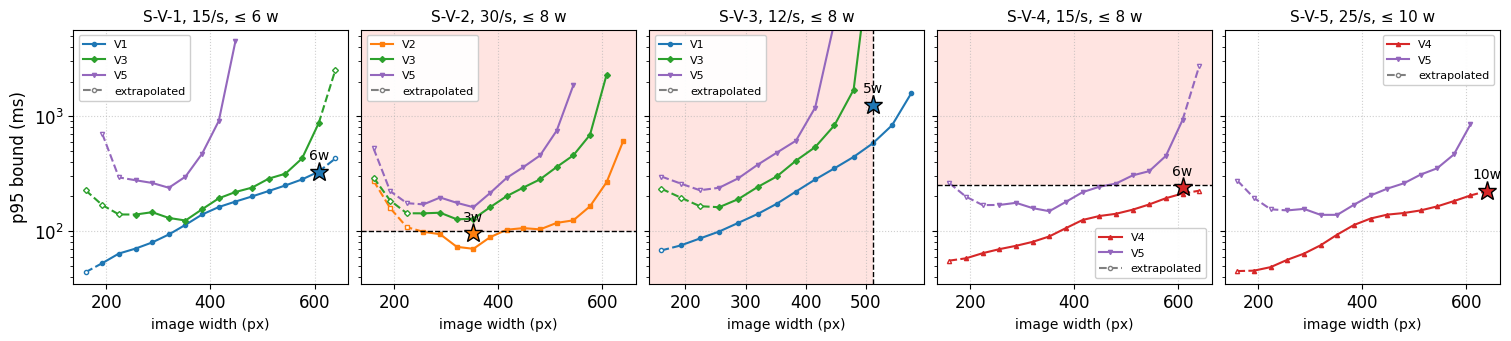

audio


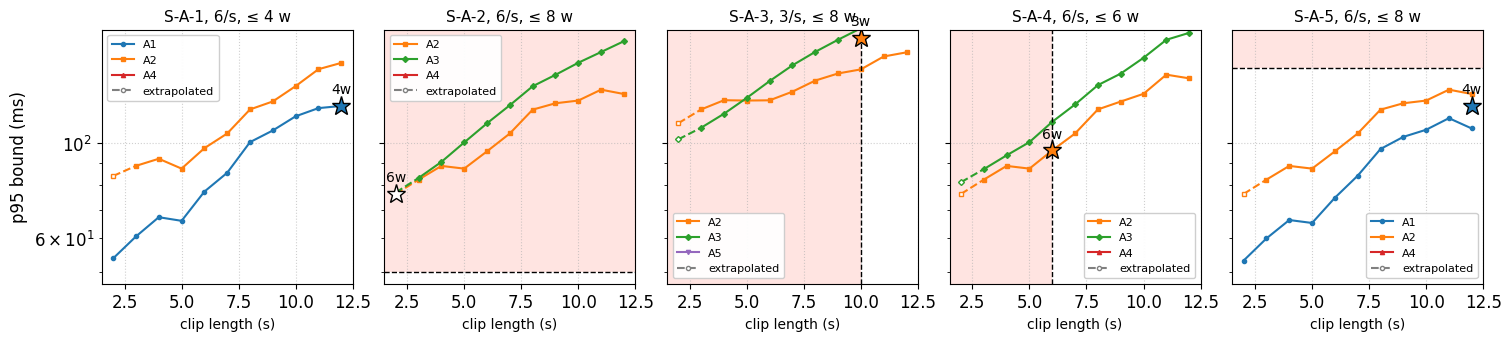

lidar


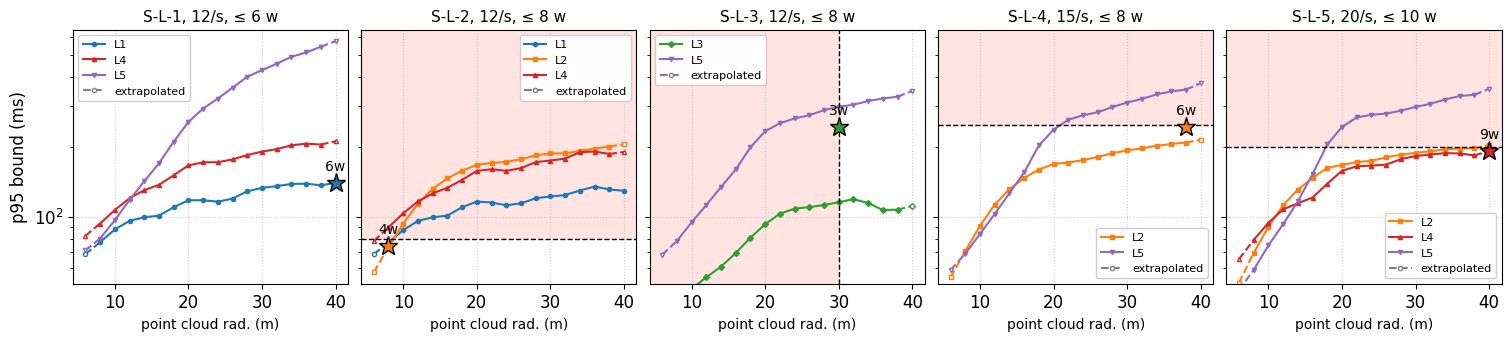

In [5]:
for app, scenarios in SCENARIOS.items():
    print(app)   # above the figure, not in it (no title in a paper figure)
    sp.tradeoff_figure({s.name: compositions[s.name] for s in scenarios}, plans, scenarios, app, WORKER_BUDGET,
                       name=f"c2_slo_plans_{app}" if WRITE_DEPLOYED_FILES else None)

**Configurations to deploy.** `statics/slo_planning/c2_plans_old.csv` and the figures `c2_slo_plans_<application>` hold the plans of the first deployment (C.2d), which come from earlier models of B.1 and from SLSQP (`statics/slo_planning/README.md`). The cell below writes the plans above, in the knob names of the campaign (`shared.data_quality`, `<node>.parallelism`, `<node>.cores` $= w_k + 0.5$, `<node>.model_size`), with the arrival rate and the predicted bound, to `statics/slo_planning/c2_plans_new.csv`. If no configuration meets the SLOs of a scenario, its plan is the *best-effort* configuration, the one with the smallest predicted bound among those that meet the other constraints (`feasible` False, `best_effort` True; hollow star in the trade-off figure).

In [6]:
# the plans above in the knob names of the campaign, to deploy them; a scenario that no configuration meets gets its best-effort
# configuration (best_effort True). Not c2_plans_old.csv: that file holds the plans of the first deployment, which C.2d reads.
deployment = sp.deployment_table(plans, {s.name: s.rate for scenarios in SCENARIOS.values() for s in scenarios})
sp.PLANS.mkdir(parents=True, exist_ok=True)
deployment.to_csv(sp.PLANS / "c2_plans_new.csv", index=False)

### C.2d. First Deployment on the Testbed

The plans in `statics/slo_planning/c2_plans_old.csv` (the first deployment, which differs from the plans above, see `statics/slo_planning/README.md`) were run on the testbed, 10 runs per scenario at the scenario's arrival rate (`statics/results_milos_v2/c2/`). This section compares their predicted p95 bound with the latencies that the requests had. The grain is the request: the end-to-end latency (ms) of every completed request of a scenario, pooled over its 10 runs.

**Table.** One row per scenario. `requests`: the number of pooled requests. `as_planned`: the deployed configuration (data quality, workers, cores, model sizes, arrival rate) is the planned one. `bound_ms`: the predicted p95 bound of the plan. `measured_p95_ms`, `measured_p99_ms`: percentiles of the pooled requests. `above_bound_pct`: the share of requests (%) slower than the bound; a p95 bound is meant to leave at most 5 % above it. `tightness`: `bound_ms / measured_p95_ms`; 1 would be an exact p95, larger values are looser. `slo_ms`: the latency SLO of the scenario, if it has one.

In [7]:
# plans of the first deployment (statics/slo_planning/c2_plans_old.csv) and the requests of their testbed runs (statics/results_milos_v2/c2/)
deployed = pd.read_csv(sp.PLANS / "c2_plans_old.csv")
scenario_by_name = {s.name: s for scenarios in SCENARIOS.values() for s in scenarios}
measured = sp.measured_c2(deployed)
display(sp.testbed_table(deployed, measured, scenario_by_name).set_index(["application", "scenario"])
        .style.format(dict(requests="{:,}", bound_ms="{:.0f}", measured_p95_ms="{:.0f}", measured_p99_ms="{:.0f}",
                           above_bound_pct="{:.2f}", tightness="{:.2f}", slo_ms="{:.0f}"), na_rep="–"))

**Figure (alternative to the table).** One figure per application, one panel per scenario. x axis: end-to-end latency $x$ (ms). y axis (log scale, shared within a figure): the share of the scenario's pooled requests that were slower than $x$, so the blue curve starts at 1 and falls; its height at $x$ is the probability that a request exceeds $x$. Dotted horizontal line: the share 0.05 that a p95 bound may leave above it. Red vertical line: the predicted p95 bound of the deployed plan. Dashed vertical line: the latency SLO, if the scenario has one. Where the blue curve crosses 0.05 is the measured p95; the red line lies right of that crossing if the bound is at least the measured p95, and the horizontal distance between them is the looseness of the bound.

vision


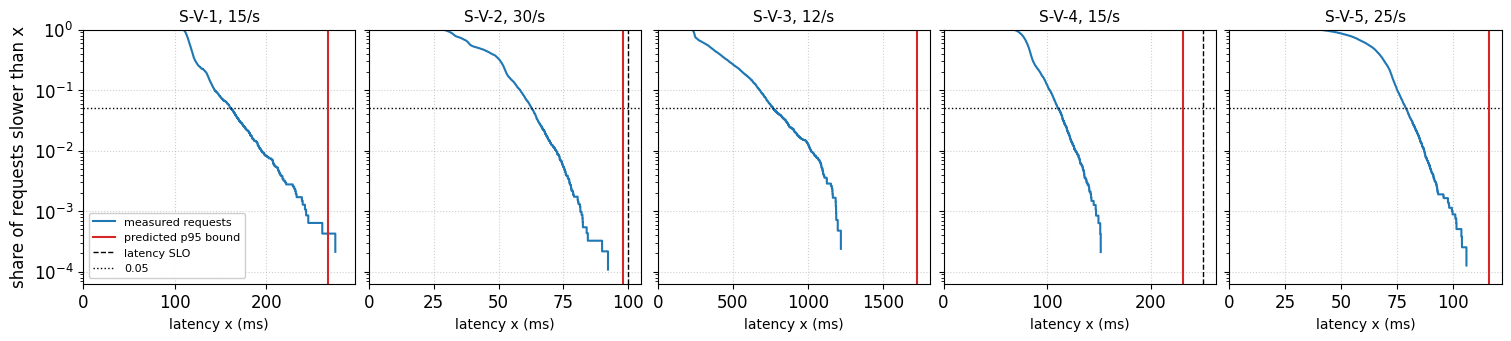

audio


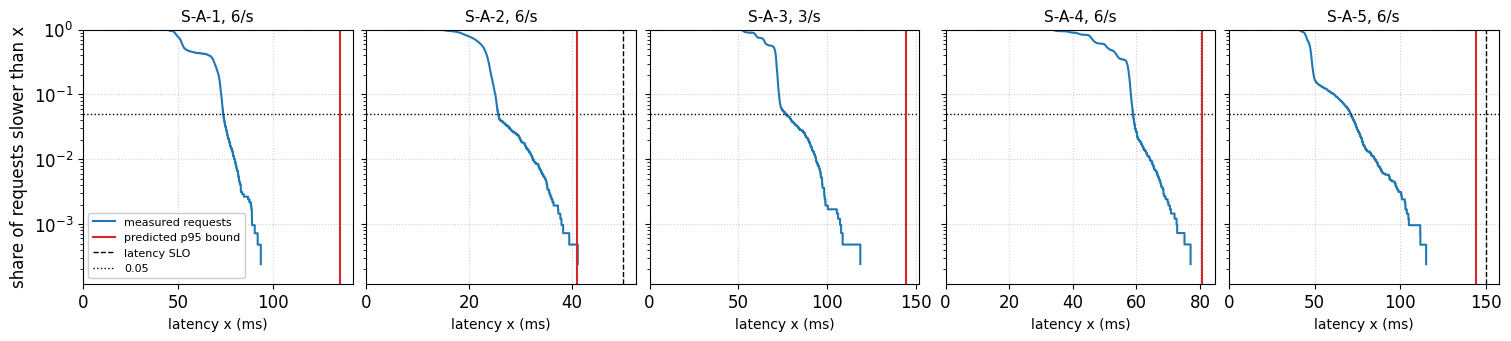

lidar


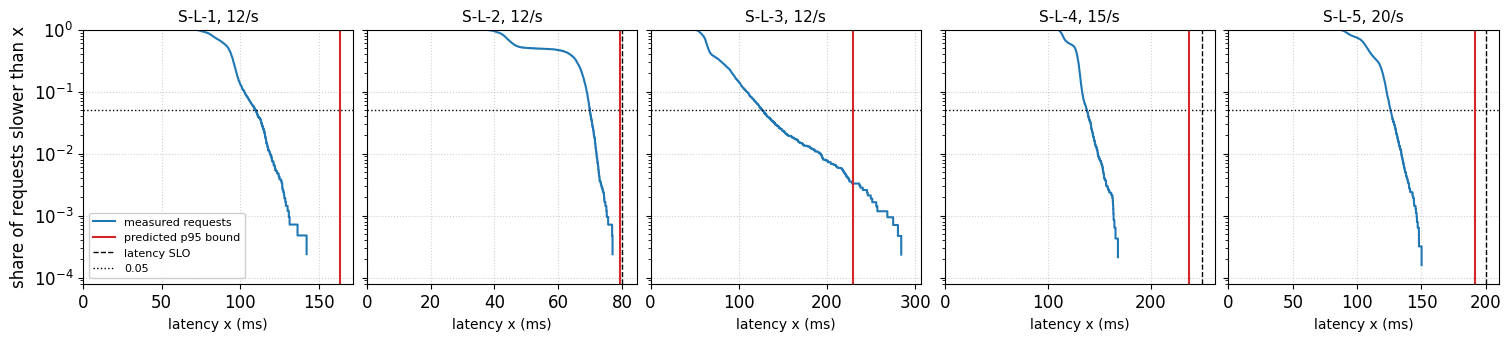

In [8]:
for app, scenarios in SCENARIOS.items():
    print(app)   # above the figure, not in it (no title in a paper figure)
    sp.testbed_figure(measured, deployed, scenarios, app)   # name=...: not exported until you pick table or figure

**Measurement in the trade-off panel.** The trade-off panel of C.2c (current plans, stars) plus two markers at the data quality $q$ of the first deployment's plan: a hollow diamond at the p95 bound that the *current* models predict for that configuration (ms), and a box plot of its measured requests (ms): the box runs from the 25th to the 75th percentile with the median, the whiskers reach the most extreme request within 1.5 interquartile ranges of the box, the requests beyond them are points, and the magenta bar, wider than the box, is the 95th percentile. The diamond is therefore comparable with the lines and stars of the panel, which come from the same models. The vertical distance between the diamond and the bar at the 95th percentile is the looseness of that bound. The stars and the markers belong to different configurations.

vision


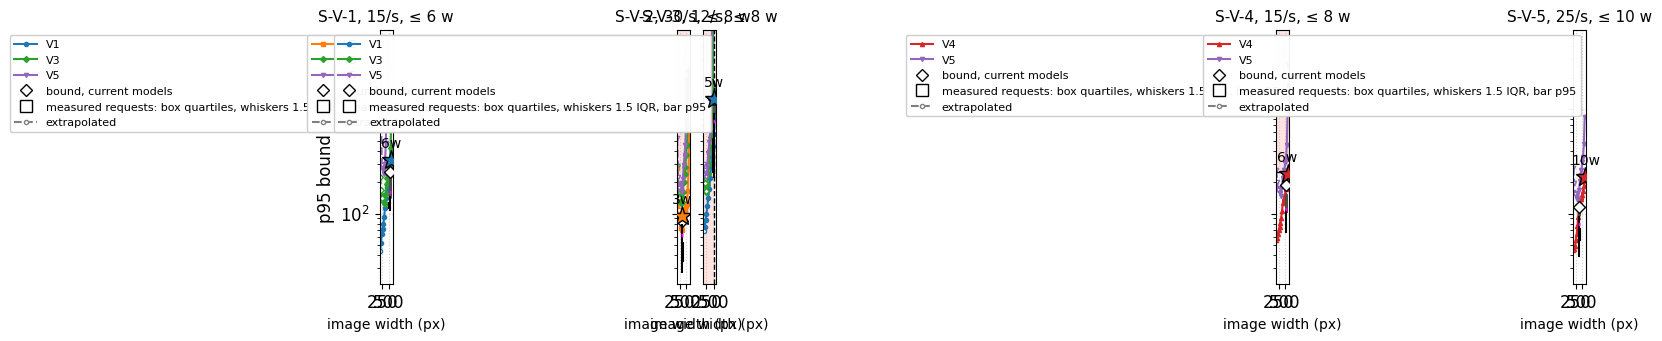

audio


C:\Users\boris\development\composable-autonomous-offerings\venv\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


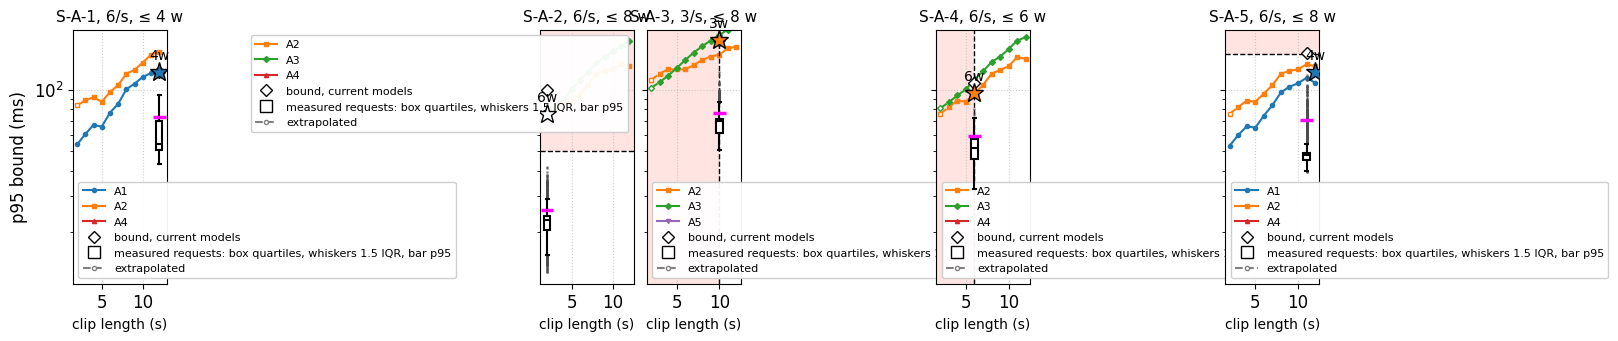

lidar


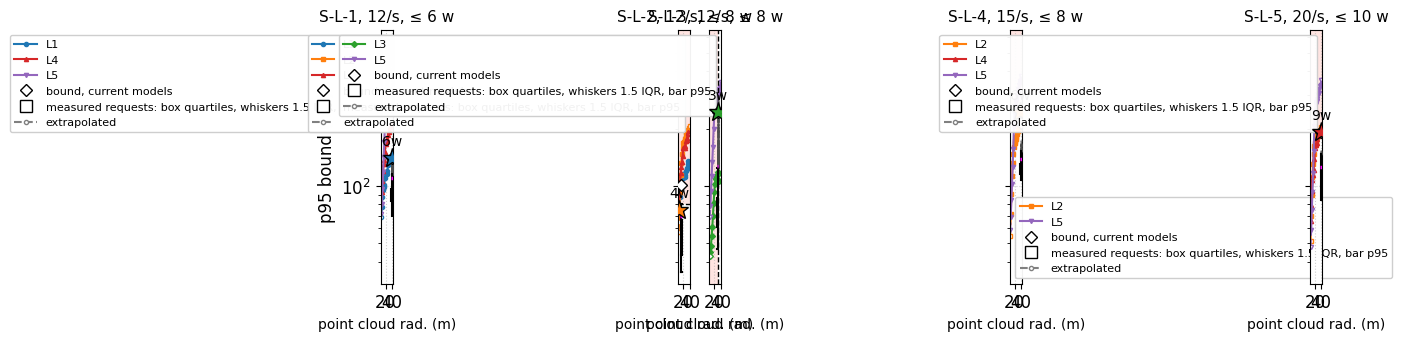

In [9]:
for app, scenarios in SCENARIOS.items():
    print(app)   # above the figure, not in it (no title in a paper figure)
    sp.tradeoff_figure({s.name: compositions[s.name] for s in scenarios}, plans, scenarios, app, WORKER_BUDGET,
                       measured=measured, deployed=deployed)

**Selected panels.** One panel per application as a figure of its own, chosen where the plan of C.2c and the first deployment have (almost) the same configuration, so that the star is also the predicted bound of the measured configuration and the diamond is left out. The three figures stand side by side in the width of one evaluation figure (`tradeoff_third_figures`): they have the height of an evaluation figure and equally wide plot areas, and every file is as wide as its own axis labels need. The x label gives only the unit of $q$ (px: vision, s: audio, m: lidar), the left margin holds only the tick labels (thousands as 1k, 10k), and only the first figure (audio) names the vertical axis, which in all three is the predicted p95 bound (ms, log scale, its own range per figure). The legends list the compositions and, split between the figures because all of them in one legend would be wider than a plot, the symbols: in the audio figure the dashed line (the SLO limit) and the star (the target configuration, labeled with its number of workers $w$), in the vision figure the box plot of the latency of the measured requests of the first deployment (box: 25th to 75th percentile with the median, whiskers: the most extreme request within 1.5 interquartile ranges of the box, points: requests beyond them) and the magenta bar, wider than the box (their 95th percentile, $P_{95}$). The red zone is where the SLO of the scenario would be violated (above the latency limit, left of the quality limit), as in the other figures. Stars are drawn on top of everything else. A legend that would hide lines extends the top of the logarithmic axis. A dashed line with hollow markers is where $q$ lies outside the training runs of a service of the composition. Two panels have a quality SLO (vision S-V-3: at least 512 px with the larger model, the vertical dashed line; audio S-A-3: at least 10 s), one a latency SLO (lidar S-L-5: p95 at most 200 ms, the horizontal dashed line). The printed line above the figures gives the star's bound and the bound of the first deployment's configuration under the same models.

S-A-3 music archive: star 175.7 ms, deployed configuration 175.7 ms
S-V-3 forensic detail: star 1261.6 ms, deployed configuration 1261.6 ms
S-L-5 robotaxi: star 192.7 ms, deployed configuration 191.9 ms
legend_inside: the legend hides 2 points or bands at its best location (upper left)
legend_inside: the legend hides 5 points or bands at its best location (upper left)


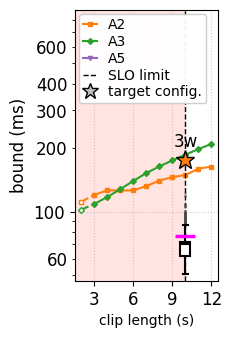

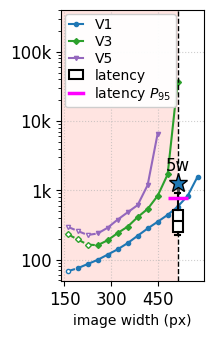

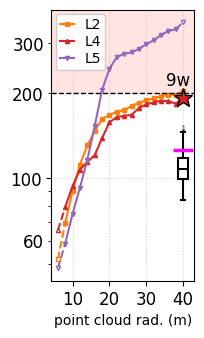

In [10]:
# in the order of the figures, left to right; plan = deployed configuration (almost)
SELECTED = {"audio": "S-A-3 music archive", "vision": "S-V-3 forensic detail", "lidar": "S-L-5 robotaxi"}
for app, name in SELECTED.items():
    star = plans[(app, name)].iloc[0]["latency_ms"]
    diamond = sp._measurement(scenario_by_name[name], compositions[name], measured, deployed)[1]   # current-model bound of the deployed configuration
    print(f"{name}: star {star:.1f} ms, deployed configuration {diamond:.1f} ms")   # printed above the figures, not in them
# the legends also describe the symbols of all three figures (sp._panel_notes), split between the figures: all four entries in one legend
# are wider than a plot
sp.tradeoff_third_figures(SELECTED, compositions, plans, scenario_by_name, WORKER_BUDGET, measured, deployed,
                          notes={"audio": ["slo", "plan"], "vision": ["box", "bar"]})